# 03 — Task (a): algorithms, tuning and behaviour

**Machine Learning · M.EIC001 · Group G51**

This notebook is the first part of the **modelling** phase of CRISP-DM for task (a), the final conference standing. It covers four things and nothing else:

- **Diversity of tasks (section 5):** the problem is solved as a regression (points percentage) and as a classification (does the team finish in the upper half of its conference?). Both are scored on the ranking they produce.
- **Diversity of algorithms (sections 5 and 7):** 16 algorithms with different language biases, 8 for each task.
- **Parameter tuning (section 6):** a systematic grid search that respects the order of time, and a measure of what it gains over the default parameters.
- **Understanding the algorithms (section 8):** what each hyperparameter does, where each algorithm overfits and what function it learns.

The data comes from `02_data_prep.ipynb`. Feature selection, the choice and final training of the model, feature importance and the white-box analysis are not here (section 9).

## 0. Setup

In [1]:
import contextlib
import io
import json
import os
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

os.environ["PYTHONWARNINGS"] = "ignore"          # the parallel workers inherit this
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 140)

RANDOM_STATE = 42

## 1. Experimental setup

**The problem.** The day before the season, predict the final regular-season rank of every team inside its conference, using only what was known before (section 1 of the EDA). The rank is obtained from the output of a model, so a regressor and a classifier end up with the same kind of result and are scored in the same way.

| Task | Label | What the model outputs | The rank is obtained by |
|---|---|---|---|
| Regression | points percentage of the team, as a z-score inside its season | the predicted z-score | sorting the teams of a conference by it |
| Classification | `top_half`: 1 if the team finishes in the upper half of its conference (53% of the rows, so the classes are balanced) | a decision value (or the log-odds) of that class | sorting the teams of a conference by it |

The classification label is easy to explain to the end user and balanced by construction, so no resampling is needed. Its cost is that it forgets the order inside each half, which the regression label keeps. A version with three tiers (top, middle, bottom) would be a middle ground and is not tried here.

**Evaluation (as in section 1).** Every model is evaluated by *walk-forward* validation: for each season from 1985 to 2009 (24 seasons, there is no 2004) the model is trained on all the seasons before it, starting in 1974, and predicts that season. The first model is trained on 11 seasons (215 rows) and the last one on 34. A random split is not used because it would train on the future. The parameters of each model are tuned *inside* its training seasons (section 6), so the season that is predicted is never used to choose anything.

- **Main measure:** Spearman correlation between the predicted and the real conference rank, computed for each conference and season and then averaged. It is also what the tuning maximises, so what is optimised is what is reported.
- **Others:** mean absolute rank error, the AUC for `top_half` (the same score ranks the teams for both tasks, so it exists for both), and for the regressors the MAE of the points percentage, as in the success criteria of section 1.
- **Reference:** B0, last season's conference rank (section 4). A model that does not beat it has not learned anything useful.
- **The unit of comparison is the season:** the 24 seasons are the sample of the paired tests of section 7, and two models are always compared on the same seasons.

## 2. Data

The features are not rebuilt here. The next cell runs the code cells of `02_data_prep.ipynb` and takes its `panel`: 842 team-seasons from 1974 to 2009, the conference rank and 12 features that only use seasons before the one that is predicted (z-scores inside the season, for last season and for the mean of the last three, plus two flags). Because it runs that notebook, a change there (new features, for example) reaches the models without copying anything. The values missing for a new franchise stay missing and are imputed inside the pipeline, fitted on the training rows only.

What is derived here are the two labels and a few columns for the baseline and the scoring. Two checks protect against leakage: no feature is a raw column of the predicted season, and `pts_pct_z_lag1` is exactly last season's z-score, rebuilt independently from the label.

In [2]:
def load_panel(path="02_data_prep.ipynb"):
    """Run the code cells of the data-preparation notebook and return its `panel` and `FEATURES`."""
    namespace = {}
    cells = json.loads(Path(path).read_text(encoding="utf-8"))["cells"]
    with contextlib.redirect_stdout(io.StringIO()):
        for cell in cells:
            if cell["cell_type"] == "code":
                source = "\n".join(line for line in "".join(cell["source"]).splitlines()
                                   if not line.lstrip().startswith(("%", "!")))
                exec(compile(source, path, "exec"), namespace)
    return namespace["panel"].copy(), list(namespace["FEATURES"])


panel, FEATURES = load_panel()
plt.close("all")

pd.Series({
    "team-seasons (rows)": len(panel),
    "seasons": f"{panel['year'].nunique()} ({panel['year'].min()}-{panel['year'].max()}, no 2004)",
    "features": len(FEATURES),
    "rows with a missing feature (new franchises)": int(panel[FEATURES].isna().any(axis=1).sum()),
}, name="panel from 02_data_prep")

team-seasons (rows)                                                 842
seasons                                         35 (1974-2009, no 2004)
features                                                             12
rows with a missing feature (new franchises)                         15
Name: panel from 02_data_prep, dtype: object

In [3]:
zscore = lambda s: (s - s.mean()) / s.std()

panel = panel.sort_values(["franchID", "year"]).reset_index(drop=True)
panel["n_conf"] = panel.groupby(["year", "confID"])["tmID"].transform("size")
panel["rel_rank"] = (panel["conf_rank"] - 1) / (panel["n_conf"] - 1)                      # 0 = best team of the conference, 1 = worst

# the two labels, one per predictive task. The ranking is always scored on `conf_rank`
panel["y_league"] = panel.groupby("year")["pts_pct"].transform(zscore)                    # regression: points % as a z-score inside the season
panel["top_half"] = (panel["rel_rank"] <= 0.5).astype(int)                                # classification: finishes in the upper half of its conference
panel["sd_pts"] = panel.groupby("year")["pts_pct"].transform("std")                       # to read an error in z-scores as points %
panel["rel_rank_lag1"] = panel.groupby("franchID")["rel_rank"].shift(1)                   # last season's relative rank, for the baseline
TARGET = {"regression": "y_league", "classification": "top_half"}

# check 1: no feature is a raw column of the season being predicted
assert all(re.search(r"_(lag\d+|avg\d+)$", f) or f == "is_new_team" for f in FEATURES)

# check 2: the lag is aligned. Rebuild last season's z-score from the label and compare it with the feature
previous = panel.groupby("franchID")["y_league"].shift(1)
has_previous = previous.notna() & (panel["year"] > panel["year"].min())
assert np.allclose(previous[has_previous], panel.loc[has_previous, "pts_pct_z_lag1"]), "pts_pct_z_lag1 is not last season's z-score"

META = panel[["year", "tmID", "confID", "conf_rank", "top_half"]]
panel = panel.sort_values(["year", "confID", "conf_rank"]).reset_index(drop=True)

pd.Series({"label of the regression: points % z-score, mean / sd": f"{panel['y_league'].mean():.2f} / {panel['y_league'].std():.2f}",
           "label of the classification: share of top_half = 1": f"{panel['top_half'].mean():.1%} (balanced by construction)"}, name="labels")

label of the regression: points % z-score, mean / sd                         0.00 / 0.98
label of the classification: share of top_half = 1      53.0% (balanced by construction)
Name: labels, dtype: str

## 3. Evaluation machinery

Scoring a ranking has a trap that is worth testing for. Many models give the same score to several teams (a tree gives one value per leaf). If ties are ranked by the order of the rows, and the rows are sorted by the real rank, the answer leaks into the prediction. While this notebook was being built, a **constant** score reached a Spearman of 1.0 and a decision tree seemed to beat every other model by 0.15. `season_scores` gives tied teams the average rank instead, and the cell below checks it with scores whose result is known: the true rank must give 1, no information must give 0 (and an AUC of 0.5), random scores must give about 0, and shuffling the rows must change nothing.

The same flaw is in `rank_scores` of `02_data_prep.ipynb` (it ranks with `method="first"` on rows sorted by the real rank), which makes its baseline about 0.013 to 0.017 higher than it should be. The baseline of section 4 is computed here without it.

The second cell has the tools used to compare models: a bootstrap interval for the mean difference between two models over the seasons, the Wilcoxon signed-rank test on the paired seasons, and the Holm correction, because every model is compared with the same reference.

In [4]:
GROUP = ["year", "confID"]


def season_scores(df, score, auc=False):
    """Spearman correlation and mean absolute rank error between the ranks predicted by `score` (higher = better) and `conf_rank`,
    and optionally the AUC of `score` for the label top_half. Everything is computed inside each conference and season, the two
    conferences are averaged, and one row per season is returned.
    Tied scores share the average rank: breaking ties by row order would use the true order, because the rows are sorted by it."""
    d = df.assign(_score=np.asarray(score, dtype=float))
    d["pred_rank"] = d.groupby(GROUP)["_score"].rank(ascending=False, method="average")
    rows = []
    for (year, _), g in d.groupby(GROUP):
        rows.append({"year": year,
                     "spearman": 0.0 if g["pred_rank"].nunique() == 1 else stats.spearmanr(g["pred_rank"], g["conf_rank"])[0],
                     "auc": roc_auc_score(g["top_half"], g["_score"]) if auc else np.nan})
    out = pd.DataFrame(rows).groupby("year").mean()
    out["rank_mae"] = (d["pred_rank"] - d["conf_rank"]).abs().groupby(d["year"]).mean()
    return out[["spearman", "rank_mae", "auc"] if auc else ["spearman", "rank_mae"]]


def prediction_scores(preds):
    """Per-season scores of a table of predictions with the columns year, tmID and score."""
    d = META.merge(preds[["year", "tmID", "score"]], on=["year", "tmID"])
    return season_scores(d, d["score"], auc=True)


def model_score(estimator, X):
    """One number per team, higher = better: the prediction of a regressor, or the decision value / log-odds of the class 'top half'."""
    if hasattr(estimator, "decision_function"):
        return estimator.decision_function(X)
    if hasattr(estimator, "predict_log_proba"):
        log_p = estimator.predict_log_proba(X)
        return np.nan_to_num(log_p[:, 1] - log_p[:, 0], nan=0.0, posinf=1e9, neginf=-1e9)
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X)[:, 1]
    return estimator.predict(X)


class RankScorer:
    """Scorer for GridSearchCV: mean per-season Spearman of the conference ranks the model predicts.
    It is the same for both tasks, which is what makes a regressor and a classifier comparable. `meta` holds year, confID, conf_rank
    and top_half of the rows that X is sliced from (X keeps their index)."""

    def __init__(self, meta):
        self.meta = meta

    def __call__(self, estimator, X, y=None):
        return season_scores(self.meta.loc[X.index], model_score(estimator, X))["spearman"].mean()


# The scoring has to be right before anything is compared with it: it needs answers that are known.
t = panel[panel["year"] >= 1985]
rng = np.random.default_rng(RANDOM_STATE)
known = {"oracle: the true conference rank": -t["conf_rank"].to_numpy(),
         "no information: the same score for every team": np.zeros(len(t)),
         "random scores": rng.normal(size=len(t))}
known = pd.DataFrame({k: season_scores(t, v, auc=True).mean() for k, v in known.items()}).T
shuffled = t.sample(frac=1, random_state=0)
order_free = np.isclose(season_scores(t, t["pts_pct_z_lag1"].fillna(0))["spearman"].mean(),
                        season_scores(shuffled, shuffled["pts_pct_z_lag1"].fillna(0))["spearman"].mean())
assert np.isclose(known.iloc[0]["spearman"], 1) and np.isclose(known.iloc[1]["spearman"], 0) and abs(known.iloc[2]["spearman"]) < 0.1
assert np.isclose(known.iloc[0]["auc"], 1) and np.isclose(known.iloc[1]["auc"], 0.5) and order_free
known

,spearman,rank_mae,auc
oracle: the true conference rank,1.000,0.000,1.000
no information: the same score for every team,0.000,3.256,0.500
random scores,-0.005,4.402,0.482


In [1]:
def paired_stats(model, baseline, n_boot=10_000, seed=0):
    """Per-season differences of two series of scores: mean, bootstrap 95% interval over seasons, wins and Wilcoxon signed-rank p-value."""
    d = (model - baseline).dropna().to_numpy()
    boot = np.random.default_rng(seed).choice(d, (n_boot, len(d))).mean(axis=1)
    return {"diff": d.mean(), "lo": np.percentile(boot, 2.5), "hi": np.percentile(boot, 97.5),
            "wins": int((d > 0).sum()), "n": len(d), "p": stats.wilcoxon(d).pvalue if np.any(d != 0) else np.nan}


def holm(p):
    """Holm-Bonferroni adjusted p-values (several models are compared with the same reference)."""
    p = pd.Series(p, dtype=float)
    adjusted, running = {}, 0.0
    for i, key in enumerate(p.dropna().sort_values().index):
        running = max(running, min(1.0, (len(p.dropna()) - i) * p[key]))
        adjusted[key] = running
    return pd.Series(adjusted).reindex(p.index)


def comparison(scores, reference):
    """One row per model: mean scores and the paired comparison with `reference` (a per-season series of Spearman values)."""
    rows = {}
    for name, s in scores.items():
        r = paired_stats(s["spearman"], reference)
        rows[name] = {"Spearman": s["spearman"].mean(), "rank MAE": s["rank_mae"].mean(), "AUC": s["auc"].mean() if "auc" in s else np.nan,
                      "Δ Spearman": r["diff"], "CI low": r["lo"], "CI high": r["hi"], "better in": f"{r['wins']}/{r['n']}", "p": r["p"]}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table["p (Holm)"] = holm(table["p"])
    return table


def forest(ax, table, title, colors=None):
    """Mean difference to the reference with its 95% interval over seasons, one line per model."""
    t = table.sort_values("Δ Spearman")
    y = np.arange(len(t))
    for yi, (name, r) in zip(y, t.iterrows()):
        ax.errorbar(r["Δ Spearman"], yi, xerr=[[r["Δ Spearman"] - r["CI low"]], [r["CI high"] - r["Δ Spearman"]]], fmt="o", capsize=3,
                    color=(colors or {}).get(name, "C0"))
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(y, t.index)
    ax.set(title=title, xlabel="Spearman minus the baseline (95% interval over seasons)")

## 4. Baselines

Three references, all computed with the information of the last season only:

- **B0, last season's conference rank** (new franchises get the mean rank) is the baseline of the success criteria of section 1 and the reference of every comparison.
- **B1, last season's points percentage** is the same information on a finer scale (it breaks the ties of the rank).
- **B2 is B1 with a rule that needs no model: franchises that have just entered the league are ranked last** instead of in the middle. There are only 9 such team-seasons among the 627 predicted ones, but they are the cases in which B0 is most wrong, and B2 is already 0.021 above it. It is the fair reference for what a model adds beyond "expansion teams are bad".

In [6]:
# The first model is trained on 1974-1984 and predicts 1985; the last one predicts 2009 (2004 is the lockout).
TEST_YEARS = [y for y in sorted(panel["year"].unique()) if y >= 1985]


def baseline_preds(kind):
    d = panel[panel["year"].isin(TEST_YEARS)]
    if kind == "rank":                 # the baseline of section 1 of the EDA: last season's conference rank, new teams get the mean rank
        score = -d["rel_rank_lag1"].fillna(0.5)
    elif kind == "points":             # the same with last season's points percentage, new teams get the league mean (z = 0)
        score = d["pts_pct_z_lag1"].fillna(0)
    else:                              # ... and new teams are ranked last, a rule that needs no model
        score = d["pts_pct_z_lag1"].where(d["is_new_team"] == 0, -1e9)
    return pd.DataFrame({"year": d["year"], "tmID": d["tmID"], "score": score})


BASELINE_NAMES = {"rank": "B0 last season's rank", "points": "B1 last season's points %", "new_last": "B2 = B1, new teams last"}
BASE = BASELINE_NAMES["rank"]
baseline_scores = {BASELINE_NAMES[k]: prediction_scores(baseline_preds(k)) for k in BASELINE_NAMES}

pd.DataFrame({name: {"Spearman": s["spearman"].mean(), "rank MAE": s["rank_mae"].mean(), "AUC (top half)": s["auc"].mean(),
                     "Spearman 1985-94": s.loc[:1994, "spearman"].mean(), "Spearman 1995-2009": s.loc[1995:, "spearman"].mean()}
              for name, s in baseline_scores.items()}).T

,Spearman,rank MAE,AUC (top half),Spearman 1985-94,Spearman 1995-2009
B0 last season's rank,0.529,2.807,0.769,0.527,0.530
B1 last season's points %,0.532,2.786,0.772,0.527,0.536
"B2 = B1, new teams last",0.550,2.731,0.779,0.553,0.547


## 5. The two tasks and the candidate algorithms

Each task has 8 algorithms, chosen so that their **language biases** differ, which is the point of testing many of them: the shape of the functions they can represent is not the same.

| Family | What it can represent | Regression | Classification |
|---|---|---|---|
| Linear | a weighted sum of the features (ElasticNet adds sparsity) | Ridge, ElasticNet | logistic regression |
| Tree | a few rules that cut one feature at a time, easy to read | decision tree | decision tree |
| Forest (bagging) | the average of many deep trees, with less variance | random forest | random forest |
| Boosting | trees added one by one, each correcting the previous ones | gradient boosting | gradient boosting |
| Kernel | smooth functions of the distance to the training points | SVR (RBF) | SVC (RBF) |
| Instances | the average of the most similar past team-seasons | k-NN | k-NN |
| Neural network | smooth non-linear combinations of the features | MLP | MLP |
| Probabilistic | class densities with independent features | | Gaussian naive Bayes |

Every algorithm is a `Pipeline`: median imputation (fitted on the training rows), a robust scaler for the algorithms that depend on the scale of the features (linear, kernel, instances and neural network, as decided in section 5.5 of the EDA) and the model. The table shows what is tuned. Fixed in all runs: 200 trees in the forests, `subsample = 0.8` in boosting and a fixed random seed.

In [7]:
N_INNER = 6        # validation seasons of the tuning inside every training set


def pipe(model, scale):
    """Median imputation (fitted on the training rows only), a robust scaler for the models that need one, then the model."""
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", RobustScaler()))
    return Pipeline(steps + [("model", model)])


# name: (task, family, language bias, pipeline, hyperparameter grid)
MODELS = {
    # ---- regression: the label is the points percentage (z-score inside the season)
    "Ridge": ("regression", "linear", "linear", pipe(Ridge(), True),
              {"model__alpha": np.logspace(-2, 3, 11)}),
    "ElasticNet": ("regression", "linear", "linear, sparse", pipe(ElasticNet(max_iter=20_000), True),
                   {"model__alpha": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1], "model__l1_ratio": [0.05, 0.2, 0.5, 0.8, 1.0]}),
    "Decision tree": ("regression", "tree", "rules (white-box)", pipe(DecisionTreeRegressor(random_state=RANDOM_STATE), False),
                      {"model__max_depth": [2, 3, 4, 6], "model__min_samples_leaf": [5, 10, 20, 40, 80]}),
    "Random forest": ("regression", "forest", "rules, bagging", pipe(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1), False),
                      {"model__max_depth": [3, 6, None], "model__min_samples_leaf": [5, 15, 30], "model__max_features": [0.33, 0.66]}),
    "Gradient boosting": ("regression", "boosting", "rules, boosting", pipe(GradientBoostingRegressor(subsample=0.8, random_state=RANDOM_STATE), False),
                          {"model__n_estimators": [25, 50, 150], "model__learning_rate": [0.01, 0.03, 0.1], "model__max_depth": [1, 2, 3]}),
    "SVR (RBF)": ("regression", "kernel", "kernel", pipe(SVR(kernel="rbf"), True),
                  {"model__C": [0.03, 0.1, 1, 10], "model__gamma": [0.01, 0.03, 0.1, 0.3], "model__epsilon": [0.1, 0.3, 0.6]}),
    "k-NN": ("regression", "k-NN", "instances", pipe(KNeighborsRegressor(), True),
             {"model__n_neighbors": [10, 20, 40, 80], "model__weights": ["uniform", "distance"]}),
    "MLP": ("regression", "MLP", "neural network", pipe(MLPRegressor(max_iter=1500, random_state=RANDOM_STATE), True),
            {"model__hidden_layer_sizes": [(8,), (16,), (16, 8)], "model__alpha": [0.01, 0.1, 1.0, 10.0]}),
    # ---- classification: the label is "finishes in the upper half of the conference"; teams are ranked by the score of that class
    "Logistic regression": ("classification", "linear", "linear", pipe(LogisticRegression(max_iter=2000), True),
                            {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]}),
    "Decision tree (clf)": ("classification", "tree", "rules (white-box)", pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), False),
                            {"model__max_depth": [1, 2, 3, 4, 6], "model__min_samples_leaf": [10, 20, 40, 80]}),
    "Random forest (clf)": ("classification", "forest", "rules, bagging", pipe(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1), False),
                            {"model__max_depth": [3, 6, None], "model__min_samples_leaf": [5, 15, 30], "model__max_features": [0.33, 0.66]}),
    "Gradient boosting (clf)": ("classification", "boosting", "rules, boosting", pipe(GradientBoostingClassifier(subsample=0.8, random_state=RANDOM_STATE), False),
                                {"model__n_estimators": [25, 50, 150], "model__learning_rate": [0.01, 0.03, 0.1], "model__max_depth": [1, 2, 3]}),
    "SVC (RBF)": ("classification", "kernel", "kernel", pipe(SVC(kernel="rbf"), True),
                  {"model__C": [0.1, 1, 10], "model__gamma": [0.003, 0.01, 0.03, 0.1, 0.3]}),
    "k-NN (clf)": ("classification", "k-NN", "instances", pipe(KNeighborsClassifier(), True),
                   {"model__n_neighbors": [10, 20, 40, 80], "model__weights": ["uniform", "distance"]}),
    "MLP (clf)": ("classification", "MLP", "neural network", pipe(MLPClassifier(max_iter=1500, random_state=RANDOM_STATE), True),
                  {"model__hidden_layer_sizes": [(4,), (8,), (16,), (16, 8)], "model__alpha": [0.01, 0.1, 1.0, 10.0]}),
    "Gaussian NB": ("classification", "Naive Bayes", "probabilistic", pipe(GaussianNB(), False),
                    {"model__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]}),
}
TASK_OF = {n: m[0] for n, m in MODELS.items()}
COLORS = {n: ("C0" if t == "regression" else "C1") for n, t in TASK_OF.items()}

pd.DataFrame({name: {"task": task, "language bias": bias, "scaled": "yes" if "scale" in est.named_steps else "no",
                     "hyperparameters tuned": ", ".join(k.replace("model__", "") for k in grid),
                     "combinations": int(np.prod([len(v) for v in grid.values()]))}
              for name, (task, _, bias, est, grid) in MODELS.items()}).T

,task,language bias,scaled,hyperparameters tuned,combinations
Ridge,regression,linear,yes,alpha,11
ElasticNet,regression,"linear, sparse",yes,"alpha, l1_ratio",30
Decision tree,regression,rules (white-box),no,"max_depth, min_samples_leaf",20
Random forest,regression,"rules, bagging",no,"max_depth, min_samples_leaf, max_features",18
Gradient boosting,regression,"rules, boosting",no,"n_estimators, learning_rate, max_depth",27
SVR (RBF),regression,kernel,yes,"C, gamma, epsilon",48
k-NN,regression,instances,yes,"n_neighbors, weights",8
MLP,regression,neural network,yes,"hidden_layer_sizes, alpha",12
Logistic regression,classification,linear,yes,C,10
Decision tree (clf),classification,rules (white-box),no,"max_depth, min_samples_leaf",20


## 6. Parameter tuning

**Approach.** For every algorithm a grid search tries all the combinations of the values in the table of section 5 (4 to 48 combinations, 42 thousand fits in total). A grid is systematic and, with ranges that cover the behaviour of each parameter (section 8), it is enough for 12 features and a few hundred rows. The search runs *inside* every walk-forward split:

1. To predict season `T`, the 6 seasons before it (`T-6 ... T-1`) are used as validation. Each one is predicted by a model trained on the seasons that precede it, so the order of time is respected.
2. The score of a combination is the mean Spearman over those 6 seasons, the same measure as in the evaluation. Tuning for the squared error or for accuracy would choose the parameters for another goal.
3. The best combination is refitted on all the seasons before `T` and predicts `T`.

**Does it matter?** Every algorithm is also run with the library defaults for the tuned parameters, and the difference is tested over the 24 seasons.

**How the grids were set.** The first grids were narrower. The effect plots of section 8 showed that for several algorithms the best value was at the edge of the grid (the number of boosting rounds, the penalty of the neural network, the leaf size of the tree, the width of the RBF kernel), so the ranges were widened until the best value was inside, or until the grid could not go further for a reason that is not the algorithm (k-NN is limited by the size of the smallest training set, about 90 rows) or because it already holds the simplest model (the boosting classifier). This used the validation scores of the first pass, which come from the same walk-forward splits, so the final numbers are very slightly optimistic.

In [8]:
def _fold(name, data, test_year, tune, features):
    """One outer split: tune on the seasons before `test_year` (walk-forward inside them), refit, predict that season."""
    task, _, _, estimator, grid = MODELS[name]
    target = TARGET[task]
    seasons = np.sort(data.loc[data["year"] < test_year, "year"].unique())
    train, test = data[data["year"] < test_year], data[data["year"] == test_year]
    years = train["year"].to_numpy()
    out = {"fold": {"year": test_year, "n_train_seasons": len(seasons)}}
    if tune:
        inner = [(np.flatnonzero(years < v), np.flatnonzero(years == v)) for v in seasons[-N_INNER:]]   # each validation season is predicted from the earlier ones
        search = GridSearchCV(estimator, grid, cv=inner, scoring=RankScorer(train), refit=True, n_jobs=1)
        search.fit(train[features], train[target])
        best = search.best_estimator_
        out["fold"].update(inner=search.best_score_, params=search.best_params_)
        out["cv"] = pd.concat([pd.DataFrame(list(search.cv_results_["params"])).rename(columns=lambda c: c.replace("model__", "")),
                               pd.Series(search.cv_results_["mean_test_score"], name="inner_score")], axis=1).assign(test_year=test_year)
    else:
        best = clone(estimator).fit(train[features], train[target])          # every grid parameter at the library default
    score = model_score(best, test[features])
    out["preds"] = pd.DataFrame({"year": test_year, "tmID": test["tmID"].to_numpy(), "score": score,
                                 "y": test[target].to_numpy(), "sd_pts": test["sd_pts"].to_numpy()})
    out["fold"]["train_spearman"] = season_scores(train, model_score(best, train[features]))["spearman"].mean()
    return out


def walk_forward(name, tune=True, years=TEST_YEARS, features=FEATURES, data=panel):
    """Nested walk-forward evaluation of one algorithm: one outer split per test season, in parallel."""
    folds = Parallel(n_jobs=-1)(delayed(_fold)(name, data, y, tune, features) for y in years)
    return {"preds": pd.concat([f["preds"] for f in folds], ignore_index=True),
            "folds": pd.DataFrame([f["fold"] for f in folds]).set_index("year"),
            "cv": pd.concat([f["cv"] for f in folds], ignore_index=True) if tune else None}


TUNED, DEFAULT = {}, {}
for name in MODELS:
    t0 = time.time()
    TUNED[name] = walk_forward(name)
    DEFAULT[name] = walk_forward(name, tune=False)
    print(f"{name:24s} {time.time() - t0:5.0f} s")

Ridge                       50 s


ElasticNet                  53 s


Decision tree               39 s


Random forest              253 s


Gradient boosting           58 s


SVR (RBF)                   26 s


... (6 outputs left out)

SVC (RBF)                    8 s


k-NN (clf)                   3 s


MLP (clf)                  220 s


Gaussian NB                  8 s


In [9]:
# the cost of the search: fits per model = combinations x validation seasons x test seasons (+ one refit per test season)
cost = pd.DataFrame({n: {"combinations": int(np.prod([len(v) for v in grid.values()]))} for n, (_, _, _, _, grid) in MODELS.items()}).T
cost["fits"] = cost["combinations"] * N_INNER * len(TEST_YEARS) + len(TEST_YEARS)
print(f"{int(cost['fits'].sum()):,} model fits in total ({len(TEST_YEARS)} test seasons x {N_INNER} validation seasons per search)")


def chosen_values(run):
    """Most chosen value of every hyperparameter across the test seasons, and the share of seasons that chose it."""
    p = pd.DataFrame(list(run["folds"]["params"])).rename(columns=lambda c: c.replace("model__", "")).map(
        lambda v: "None" if v is None else (f"{v:.3g}" if isinstance(v, (float, np.floating)) else str(v)))
    return {c: f"{p[c].mode()[0]} ({(p[c] == p[c].mode()[0]).mean():.0%})" for c in p}


pd.DataFrame({"most chosen value (share of the 24 seasons)": {n: ", ".join(f"{k} = {v}" for k, v in chosen_values(r).items()) for n, r in TUNED.items()}})

42,432 model fits in total (24 test seasons x 6 validation seasons per search)


,most chosen value (share of the 24 seasons)
Ridge,alpha = 0.316 (38%)
ElasticNet,"alpha = 0.01 (42%), l1_ratio = 0.8 (33%)"
Decision tree,"max_depth = 4 (58%), min_samples_leaf = 10 (33%)"
Random forest,"max_depth = 3 (50%), max_features = 0.66 (71%), min_samples_leaf = 30 (67%)"
Gradient boosting,"learning_rate = 0.01 (58%), max_depth = 3 (50%), n_estimators = 150 (50%)"
SVR (RBF),"C = 10 (50%), epsilon = 0.1 (33%), gamma = 0.03 (58%)"
k-NN,"n_neighbors = 80 (50%), weights = distance (71%)"
MLP,"alpha = 0.1 (38%), hidden_layer_sizes = (16,) (42%)"
Logistic regression,C = 30 (33%)
Decision tree (clf),"max_depth = 3 (46%), min_samples_leaf = 10 (46%)"


,default,tuned,Δ Spearman,CI low,CI high,p,p (Holm)
ElasticNet,0.028,0.560,0.532,0.472,0.589,0.000,0.000
Decision tree (clf),0.282,0.493,0.211,0.143,0.288,0.000,0.000
MLP,0.407,0.541,0.134,0.084,0.187,0.000,0.003
Decision tree,0.404,0.529,0.126,0.049,0.203,0.005,0.048
MLP (clf),0.438,0.549,0.112,0.062,0.162,0.000,0.002
k-NN (clf),0.464,0.549,0.085,0.049,0.120,0.000,0.006
Gradient boosting (clf),0.458,0.520,0.062,0.021,0.102,0.010,0.086
k-NN,0.474,0.521,0.047,0.014,0.077,0.010,0.086
Gradient boosting,0.510,0.550,0.040,0.017,0.065,0.004,0.039
SVR (RBF),0.510,0.542,0.032,0.008,0.057,0.034,0.204


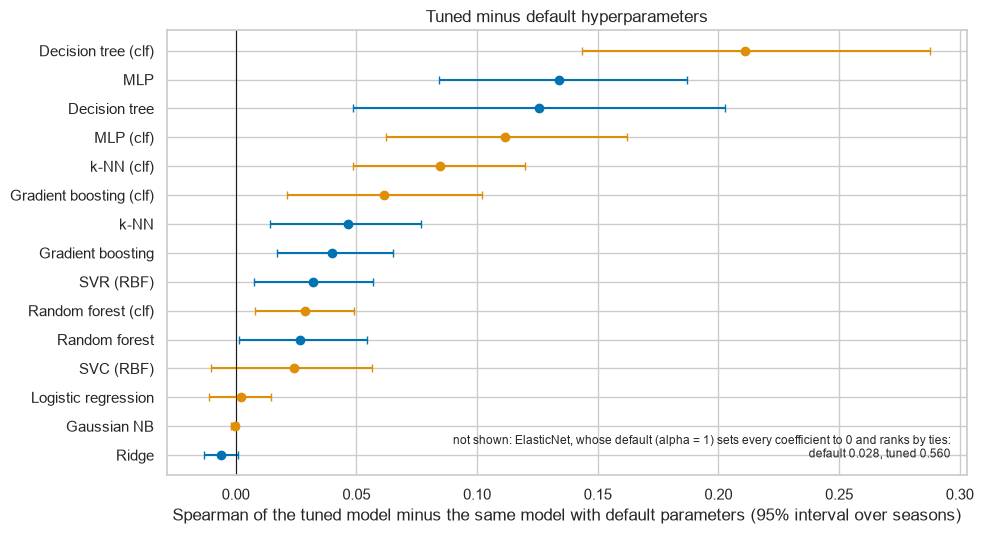

In [10]:
default_scores = {n: prediction_scores(r["preds"]) for n, r in DEFAULT.items()}
tuned_scores = {n: prediction_scores(r["preds"]) for n, r in TUNED.items()}
gain = pd.DataFrame({n: {"default": default_scores[n]["spearman"].mean(), "tuned": tuned_scores[n]["spearman"].mean(),
                         **{k: v for k, v in paired_stats(tuned_scores[n]["spearman"], default_scores[n]["spearman"]).items() if k in ("diff", "lo", "hi", "p")}}
                     for n in MODELS}).T.rename(columns={"diff": "Δ Spearman", "lo": "CI low", "hi": "CI high"})
gain["p (Holm)"] = holm(gain["p"])

fig, ax = plt.subplots(figsize=(10, 5.5))
forest(ax, gain.drop(index="ElasticNet"), "Tuned minus default hyperparameters", COLORS)
ax.set_xlabel("Spearman of the tuned model minus the same model with default parameters (95% interval over seasons)")
ax.text(0.98, 0.04, "not shown: ElasticNet, whose default (alpha = 1) sets every coefficient to 0 and ranks by ties:\n"
        f"default {gain.loc['ElasticNet', 'default']:.3f}, tuned {gain.loc['ElasticNet', 'tuned']:.3f}",
        transform=ax.transAxes, ha="right", fontsize=8.5)
plt.tight_layout()
gain.sort_values("Δ Spearman", ascending=False).round(3)

- **Tuning matters a lot for flexible algorithms and not at all for smooth ones.** The defaults of the single tree (no depth limit, leaves of one row), the neural network (100 units, almost no penalty), k-NN (5 neighbours) and boosting (100 trees of depth 3) overfit, and tuning gains between 0.04 and 0.21 of Spearman: the classification tree goes from 0.28 to 0.49, the regression tree from 0.40 to 0.53, the MLP from 0.41 to 0.54 in regression and from 0.44 to 0.55 in classification, and the k-NN classifier from 0.46 to 0.55. For the forests and the kernel machines the gain is 0.02 to 0.03. Seven gains (counting ElasticNet's) are still significant at 5% after the Holm correction.
- **The default of ElasticNet is a trap and not a baseline.** `alpha` = 1 sets every coefficient to zero, so the model ranks by ties and gets 0.03; tuned, it is the best algorithm (0.560). It is left out of the plot so that the other bars can be read.
- **For Ridge, the logistic regression and naive Bayes tuning gains nothing** (-0.006, +0.002 and 0.000): their defaults already sit in the flat part of the curve (section 8.1). The tuned Ridge is even a little worse than the default (the interval for the difference goes from -0.013 to +0.001). Its validation score is flat for `alpha` between 0.01 and 3, so the six validation seasons choose among values that are equivalent, and the winner changes from season to season (the most chosen value, 0.316, wins in 38% of them).
- **The choice is not stable for many parameters.** The most chosen value of a parameter usually wins in a third to three quarters of the seasons; only naive Bayes (92%) and the distance weights of the k-NN classifier (100%) are chosen almost always. Six validation seasons are a noisy sample, which is why the validation score is above the test score for every algorithm (by 0.02 to 0.06, section 8.2): the best of many combinations is partly the luckiest one. A longer validation window would reduce this, at the cost of the seasons available for training.

## 7. Results of the algorithms and of the two tasks

All the algorithms, tuned as in section 6, on the 24 test seasons. The table compares each one with B0, and with B2 (the rule that needs no model), season by season: the mean difference with a bootstrap 95% interval over the seasons, the number of seasons in which the model is better and the Wilcoxon p-value, with the Holm correction for all the rows of the table.

In [11]:
reference = baseline_scores[BASE]["spearman"]
all_scores = {**{n: s for n, s in baseline_scores.items() if n != BASE}, **tuned_scores}
results = comparison(all_scores, reference)
print(f"B0 (the baseline), {len(TEST_YEARS)} seasons: Spearman {reference.mean():.3f}, rank MAE {baseline_scores[BASE]['rank_mae'].mean():.2f}, AUC {baseline_scores[BASE]['auc'].mean():.3f}")

# the regression models are also fits of the points percentage: error of the z-score read in points %
fit_mae = {n: ((r["preds"]["score"] - r["preds"]["y"]).abs() * r["preds"]["sd_pts"]).mean() for n, r in TUNED.items() if TASK_OF[n] == "regression"}
results["MAE of points % (fit)"] = pd.Series(fit_mae)

# B2 needs no model, so it is the fair reference for what a model adds
b2 = baseline_scores[BASELINE_NAMES["new_last"]]["spearman"]
results["Δ vs B2"] = pd.Series({n: (s["spearman"] - b2).mean() for n, s in tuned_scores.items()})
results["p vs B2"] = pd.Series({n: paired_stats(s["spearman"], b2)["p"] for n, s in tuned_scores.items()})
results.insert(0, "task", results.index.map(lambda n: TASK_OF.get(n, "baseline")))
results.sort_values("Spearman", ascending=False).round(3)

B0 (the baseline), 24 seasons: Spearman 0.529, rank MAE 2.81, AUC 0.769


,task,Spearman,rank MAE,AUC,Δ Spearman,CI low,CI high,better in,p,p (Holm),MAE of points % (fit),Δ vs B2,p vs B2
ElasticNet,regression,0.560,2.685,0.785,0.031,-0.001,0.061,18/24,0.034,0.612,0.059,0.011,0.152
Ridge,regression,0.556,2.713,0.780,0.027,-0.005,0.059,15/24,0.079,1.000,0.060,0.006,0.527
Gradient boosting,regression,0.550,2.697,0.776,0.021,-0.012,0.052,16/24,0.166,1.000,0.063,0.000,0.584
"B2 = B1, new teams last",baseline,0.550,2.731,0.779,0.021,0.006,0.038,15/24,0.039,0.657,NaN,NaN,NaN
MLP (clf),classification,0.549,2.709,0.774,0.021,-0.016,0.059,14/24,0.390,1.000,NaN,-0.000,0.966
k-NN (clf),classification,0.549,2.697,0.777,0.020,-0.009,0.048,16/24,0.197,1.000,NaN,-0.001,0.726
Gaussian NB,classification,0.545,2.736,0.772,0.016,-0.015,0.047,14/24,0.303,1.000,NaN,-0.004,0.900
Random forest,regression,0.544,2.689,0.775,0.015,-0.019,0.050,14/24,0.422,1.000,0.061,-0.005,0.944
SVR (RBF),regression,0.542,2.737,0.768,0.013,-0.022,0.049,14/24,0.449,1.000,0.061,-0.007,0.747
MLP,regression,0.541,2.711,0.765,0.012,-0.029,0.053,14/24,0.546,1.000,0.061,-0.008,0.966


Friedman test over the 16 algorithms and 24 seasons: chi2 = 21.1, p = 0.132


best regressor ElasticNet vs best classifier MLP (clf): Spearman difference +0.011, 95% interval [-0.007, +0.028], better in 16/24 seasons, Wilcoxon p = 0.20


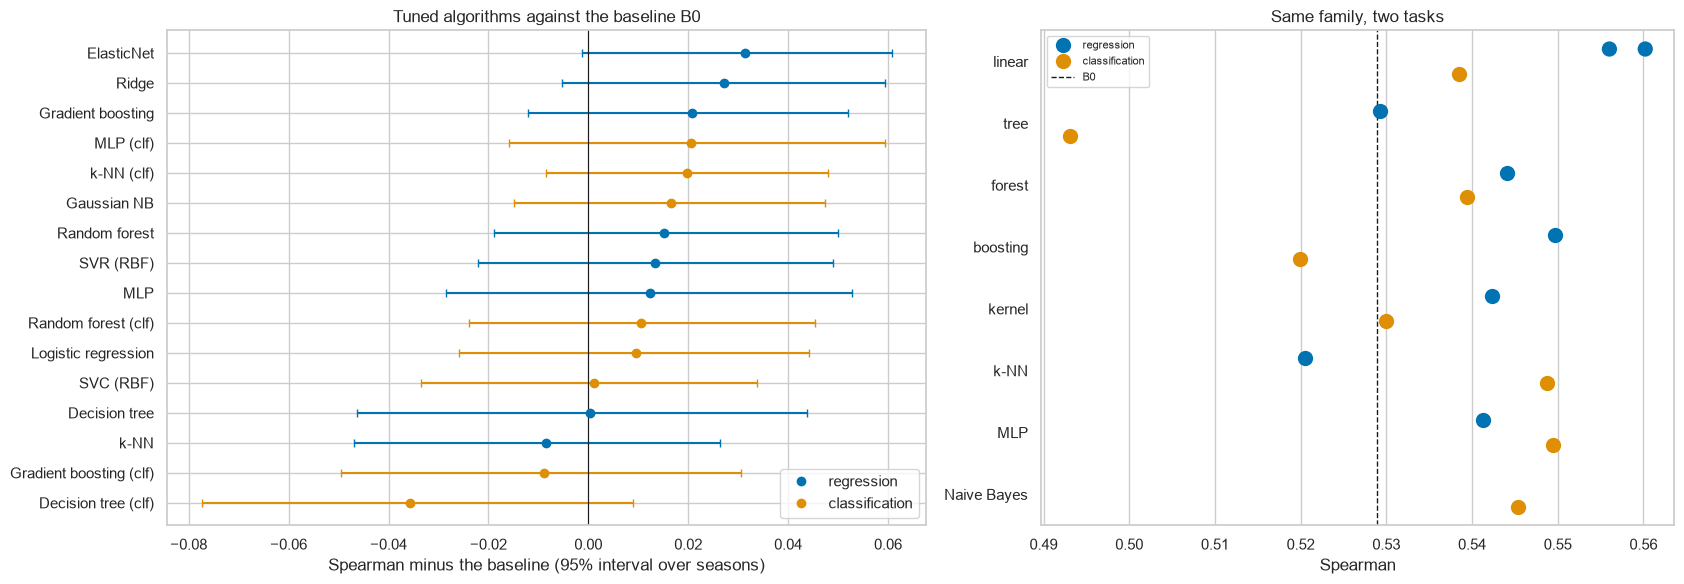

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.2, 1]})
forest(axes[0], results.drop(index=[n for n in results.index if n.startswith("B")]), "Tuned algorithms against the baseline B0",
       {**COLORS, **{n: "k" for n in results.index if n.startswith("B")}})
axes[0].plot([], [], "o", color="C0", label="regression")
axes[0].plot([], [], "o", color="C1", label="classification")
axes[0].legend(loc="lower right")

# the two tasks side by side: the same algorithm family framed as a regression and as a classification
fam = pd.DataFrame({"family": [MODELS[n][1] for n in MODELS], "task": [TASK_OF[n] for n in MODELS],
                    "Spearman": [tuned_scores[n]["spearman"].mean() for n in MODELS]})
sns.stripplot(data=fam, y="family", x="Spearman", hue="task", ax=axes[1], size=11, jitter=False, dodge=True, palette=["C0", "C1"])
axes[1].axvline(reference.mean(), color="k", ls="--", lw=1, label="B0")
axes[1].set(title="Same family, two tasks", xlabel="Spearman", ylabel="")
axes[1].legend(loc="upper left", fontsize=8)
plt.tight_layout()

friedman = stats.friedmanchisquare(*[tuned_scores[n]["spearman"] for n in MODELS])
print(f"Friedman test over the {len(MODELS)} algorithms and {len(TEST_YEARS)} seasons: chi2 = {friedman.statistic:.1f}, p = {friedman.pvalue:.3f}")
best = {task: max((n for n in MODELS if TASK_OF[n] == task), key=lambda n: tuned_scores[n]["spearman"].mean()) for task in TARGET}
duel = paired_stats(tuned_scores[best["regression"]]["spearman"], tuned_scores[best["classification"]]["spearman"])
print(f"best regressor {best['regression']} vs best classifier {best['classification']}: Spearman difference {duel['diff']:+.3f}, "
      f"95% interval [{duel['lo']:+.3f}, {duel['hi']:+.3f}], better in {duel['wins']}/{duel['n']} seasons, Wilcoxon p = {duel['p']:.2f}")

- **No algorithm is clearly better than the baseline.** The tuned algorithms are between -0.036 and +0.031 of Spearman from B0 (0.529). The best, ElasticNet, reaches 0.560 and is better than B0 in 18 of 24 seasons, with an interval for the mean difference that just includes zero (-0.001 to 0.061; p = 0.03 before the correction and 0.61 after the Holm correction for the 18 rows). The rank error goes from 2.81 positions to 2.69 and the AUC for the upper half from 0.769 to 0.785. All sixteen intervals include zero, and the Friedman test does not find differences between the 16 algorithms either (p = 0.13).
- **B2 shows how much of the gain is not learning.** The rule "new franchises last" alone reaches 0.550 (+0.021 over B0) and is the only row of the table whose interval excludes zero, with no model at all. Five algorithms reach it or come within 0.001 of it (ElasticNet, Ridge, boosting and the MLP and k-NN classifiers), and only the two linear ones are above it (+0.011 and +0.006; the best has p = 0.15 against B2). What the models found beyond B0 is mostly what the rule already knows, and the rest cannot be told from noise with 24 seasons.
- **The family decides more than the algorithm.** The linear models are the best regressors (0.556 and 0.560), followed by boosting, the forest, SVR and the MLP (0.541 to 0.550); the single tree (0.529) and k-NN (0.521) are at the level of B0 or under it. This agrees with sections 8.1 and 8.3: the signal is weak and almost linear, and flexible models only add variance.
- **Regression and classification are equivalent.** The best regressor (ElasticNet, 0.560) is 0.011 above the best classifier (MLP, 0.549), with an interval from -0.007 to 0.028, better in 16 of 24 seasons and p = 0.20. By family, the regressor is better in 5 of 7 (linear, tree, forest, boosting and kernel: +0.005 to +0.036) and the classifier in 2 (k-NN and MLP: +0.028 and +0.008). The regression label keeps the size of the gap between two teams, which the binary label throws away. A possible reason for the two exceptions is that the average of 0 and 1 labels (k-NN, MLP) is a more robust target than a z-score, but it was not tested. The AUC for the upper half is also similar (0.735 to 0.785). Which task is used matters little for the quality of the ranking; the regression also gives an estimate of the points, and it is the task defined in section 1.
- **The fit of the points percentage is the same for all the regressors.** The MAE is 0.059 to 0.063, about 6 percentage points or 10 points in 82 games, close to the standard deviation of the luck of a season (0.055, section 5.4 of the EDA). The size of the error is set by the luck in the label, and no algorithm can lower it much.

## 8. Understanding the behaviour of the algorithms

Three ways of looking inside the algorithms, all with the same walk-forward results:

1. **Effect of each hyperparameter** (8.1): the validation Spearman of the tuning for every value of every hyperparameter, averaged over the other hyperparameters and over the 24 splits. The bars are the standard error over the splits, which overlap, so they are only a guide.
2. **Complexity, training and test** (8.2): what happens to the training and the test score when the model is allowed to be more flexible, and how far apart they are for the tuned models.
3. **The function that was learned** (8.3): the out-of-sample score of each algorithm against the feature that matters most, the points percentage of the team last season.

### 8.1 What the hyperparameters do

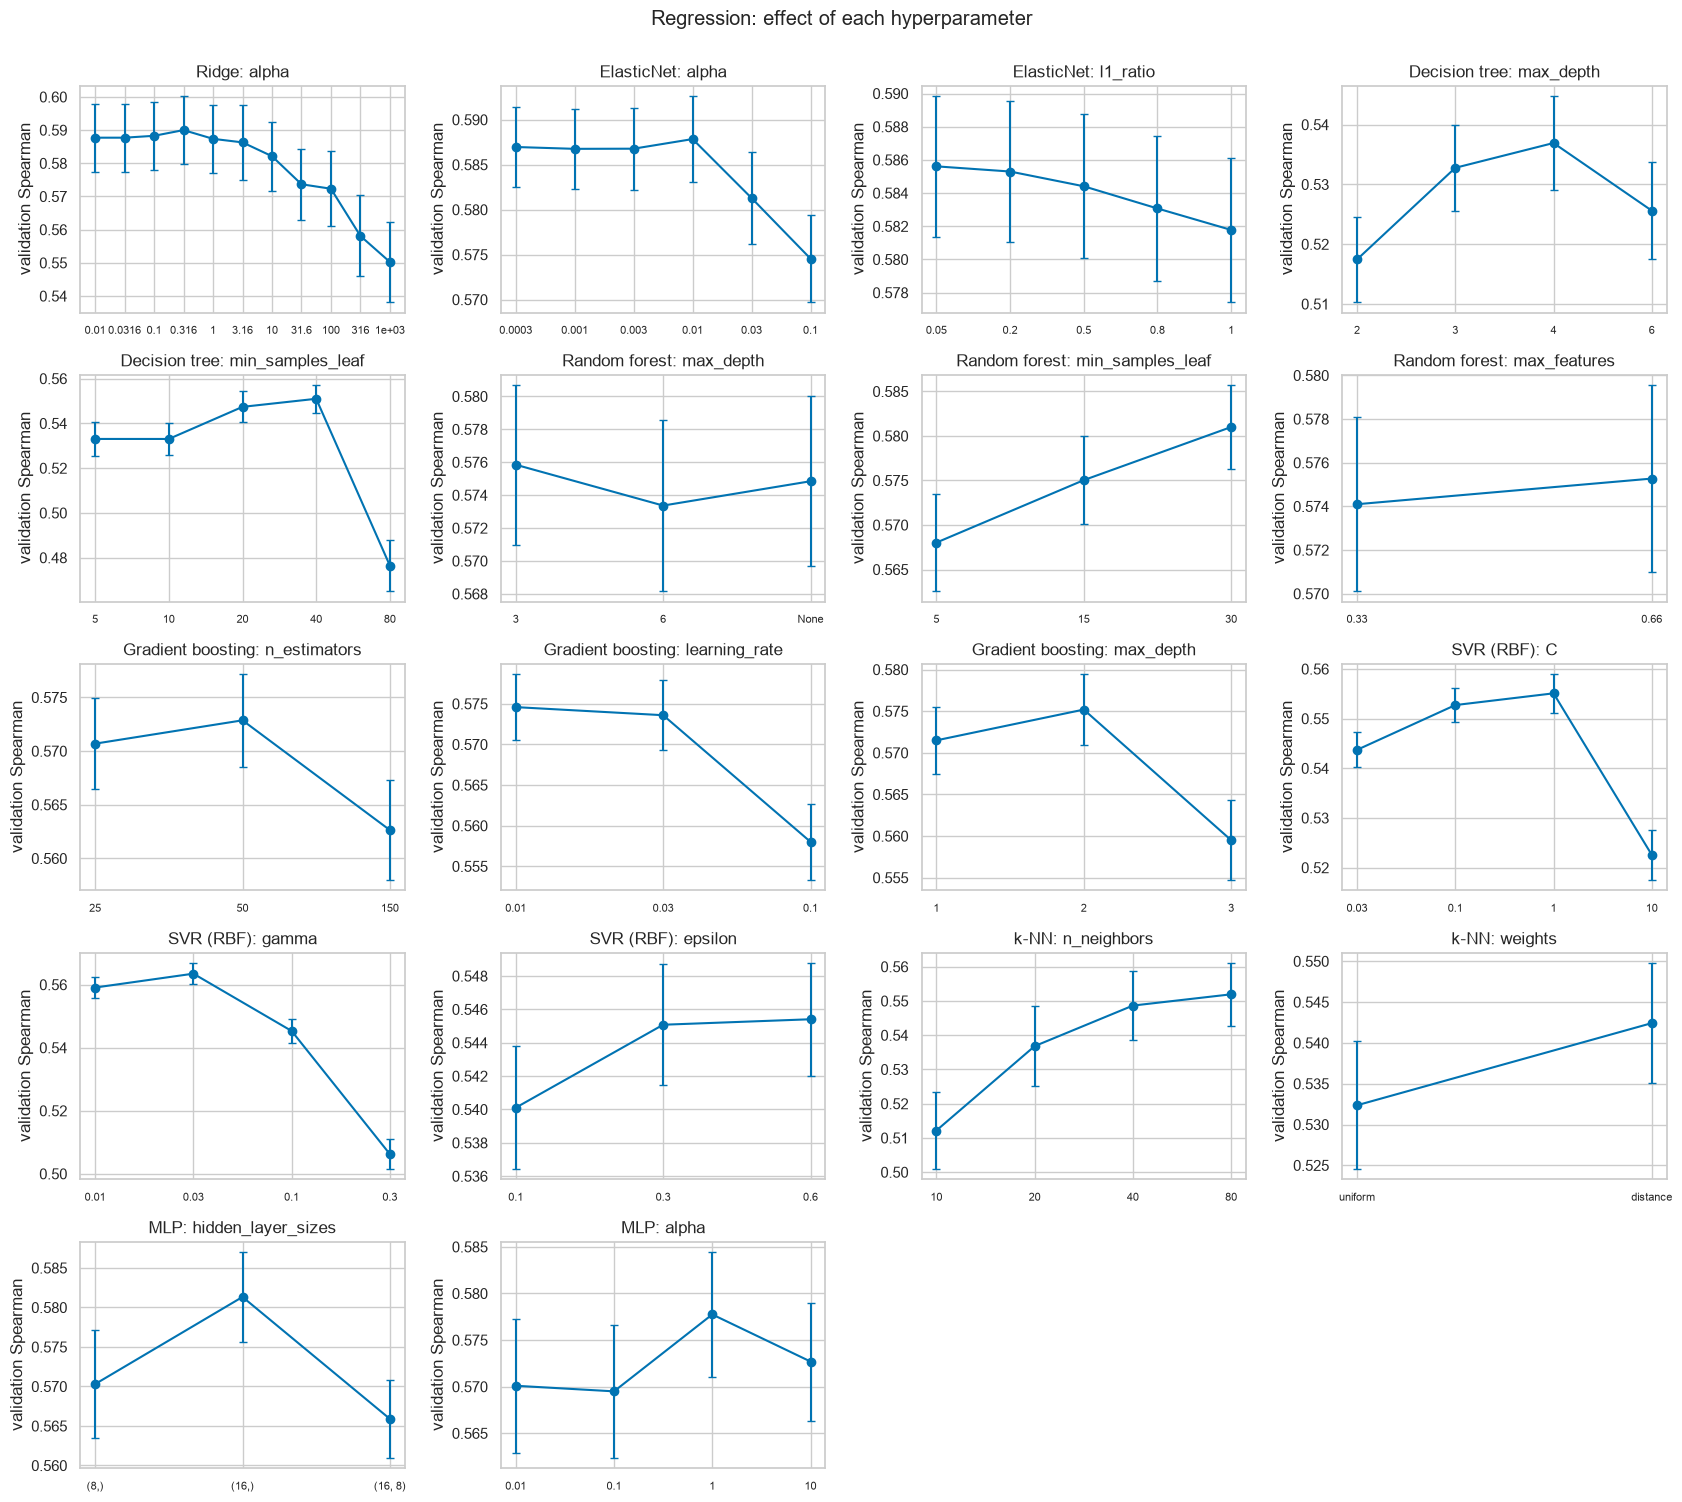

In [13]:
def label(v):
    return "None" if v is None or (isinstance(v, float) and np.isnan(v)) else (f"{v:.3g}" if isinstance(v, (float, np.floating)) else str(v))


def plot_effects(task, title):
    """Validation Spearman (inside the tuning) for each value of each hyperparameter, averaged over the other hyperparameters and the test seasons."""
    names = [n for n in MODELS if TASK_OF[n] == task]
    panels = [(m, k.replace("model__", "")) for m in names for k in MODELS[m][4]]
    rows = int(np.ceil(len(panels) / 4))
    fig, axes = plt.subplots(rows, 4, figsize=(17, 3.0 * rows))
    for ax, (m, p) in zip(axes.flat, panels):
        d = TUNED[m]["cv"].assign(value=lambda x: x[p].map(label))
        order = list(dict.fromkeys(d["value"]))
        g = d.groupby("value")["inner_score"].agg(["mean", "sem"]).reindex(order)
        ax.errorbar(range(len(g)), g["mean"], g["sem"], marker="o", capsize=3)
        ax.set_xticks(range(len(g)), g.index, fontsize=8, rotation=0)
        ax.set(title=f"{m}: {p}", ylabel="validation Spearman")
    for ax in list(axes.flat)[len(panels):]:
        ax.axis("off")
    fig.suptitle(title, y=1.0)
    plt.tight_layout()


plot_effects("regression", "Regression: effect of each hyperparameter")

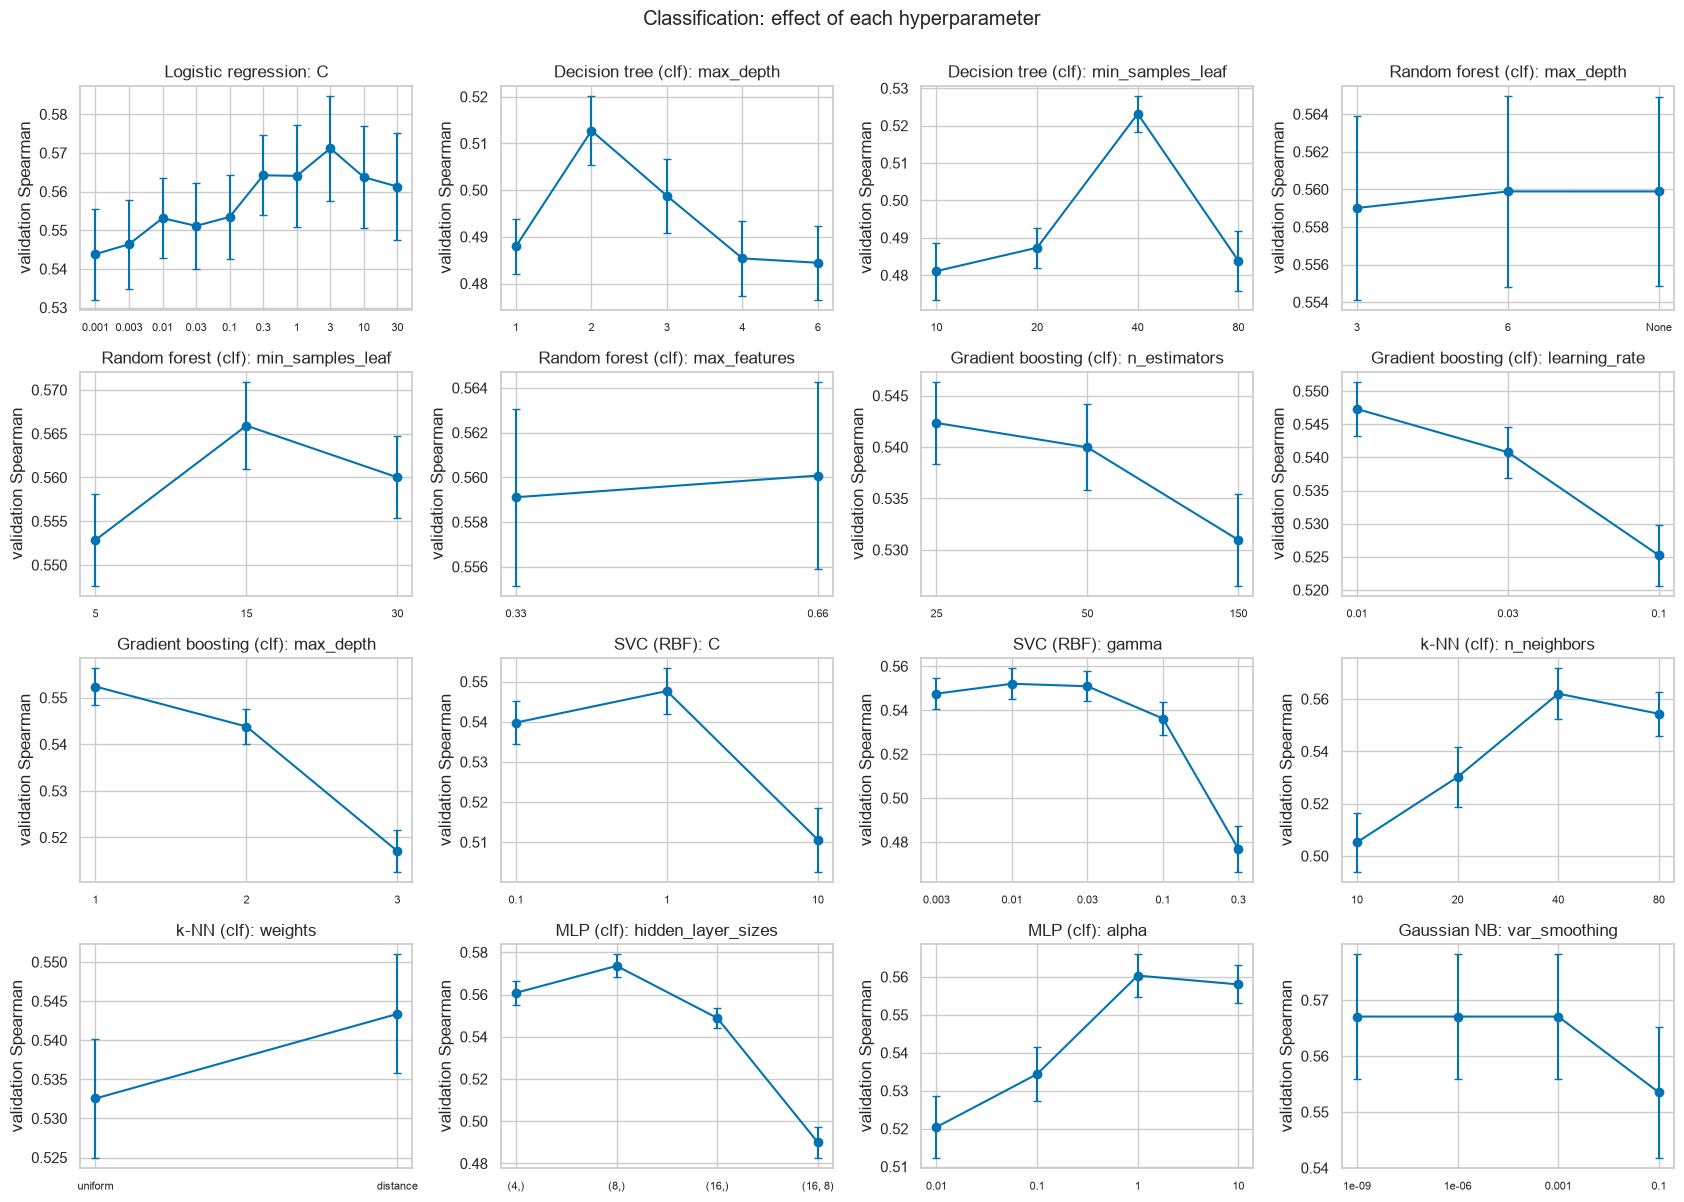

In [14]:
plot_effects("classification", "Classification: effect of each hyperparameter")

**Linear models.** Ridge is flat from `alpha` = 0.01 to about 3 and loses 0.04 as the penalty grows to 1000. With 12 features and 200 to 800 rows there is little to regularise, so any small penalty is as good as another. ElasticNet is flat until `alpha` = 0.01 and falls after it, when the L1 part starts to remove features (a more L2-like mix, `l1_ratio` = 0.05, is a little better, within the error bars): keeping all the correlated history features helps. The logistic regression behaves in the same way with `C`, the inverse of the penalty: the score rises up to `C` = 3 and stays about the same.

**Trees.** For the single tree the depth has a clear optimum (4 in regression, 2 in classification) and so does the minimum leaf size (40; 80 collapses to 0.48 because the leaves become too coarse for 200 to 800 rows). Smaller trees underfit and deeper ones memorise (section 8.2). The forests are almost insensitive to the depth and to the number of features per split: averaging many trees removes most of what tuning does for a single tree. The leaf size is the only parameter that matters, bigger is better in regression up to the edge of the grid (30) and 15 is the best in classification.

**Boosting.** Both versions prefer to learn little: low learning rates (0.01 to 0.03), few trees (25 to 50) and shallow trees (depth 1 to 2). The more flexible setting of each parameter loses between 0.01 and 0.035. The classifier ends at the corner of the grid (25 trees, rate 0.01, depth 1), the simplest model allowed, which says that boosting has little to add to what a few stumps find.

**Kernel and instances.** For SVR and SVC the width of the kernel is the parameter that matters: with `gamma` = 0.3 the model follows single teams and the score drops by 0.06 to 0.07, and a large `C` loses 0.03 to 0.04; the best values give an almost linear model (`gamma` 0.01 to 0.03, `C` = 1). k-NN needs many neighbours (with 10 it is 0.04 to 0.06 below the best), because each team-season is mostly noise. In classification 40 neighbours are better than 80; in regression the score is still rising at 80, the largest value that the smallest training sets (about 90 rows) allow. Weighting by distance is slightly better than uniform (+0.01).

**Neural network.** A small network wins: one layer of 16 units in regression and of 8 in classification are better than the two-layer network, which loses 0.015 in regression and 0.08 in classification. The L2 penalty matters in classification (`alpha` = 1 to 10; without it the classifier is 0.04 worse) and very little in regression.

**Naive Bayes** is insensitive to `var_smoothing` (it only matters at 0.1).

The common message is that this problem rewards **simple and strongly smoothed models**. The signal is weak (a quarter of the variance between teams is luck, section 5.4 of the EDA), so every parameter that adds flexibility is paid for with variance.

### 8.2 Complexity and overfitting

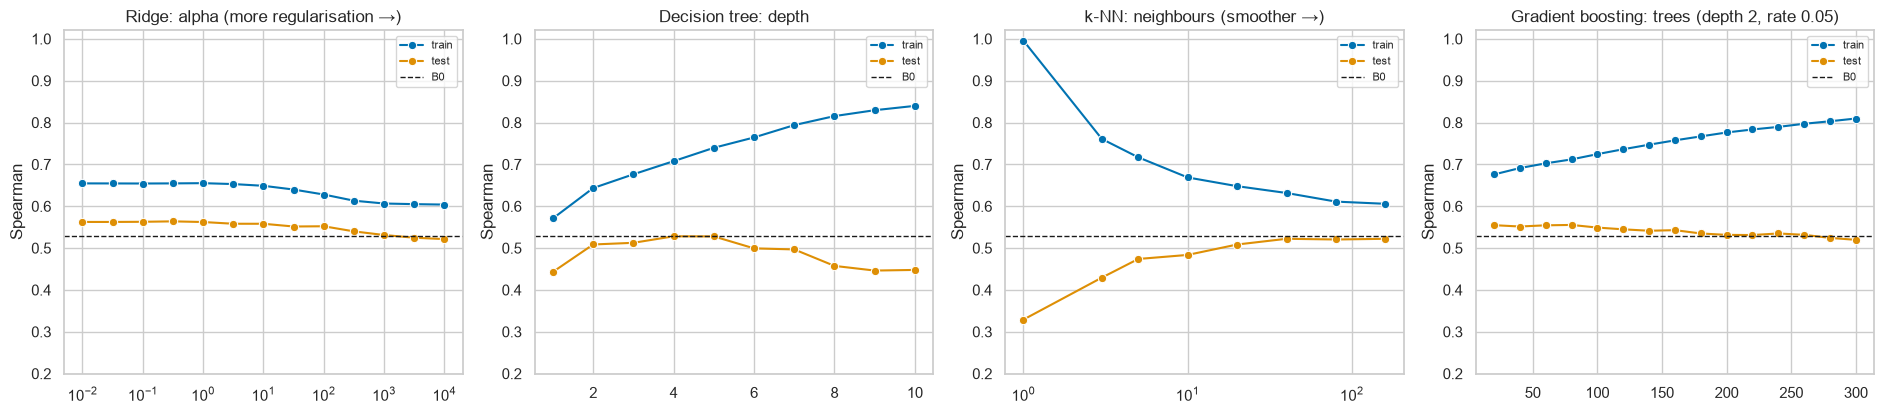

In [15]:
def _complexity_year(year, features=FEATURES):
    """Training and test Spearman as the complexity of one algorithm grows, trained once on the seasons before `year`, no tuning."""
    train, test = panel[panel["year"] < year], panel[panel["year"] == year]
    prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", RobustScaler())]).fit(train[features])
    Xtr, Xte = prep.transform(train[features]), prep.transform(test[features])
    ytr = train["y_league"]
    rows = []

    def add(model, value, ptr, pte):
        rows.extend([{"model": model, "complexity": value, "set": "train", "year": year, "spearman": season_scores(train, ptr)["spearman"].mean()},
                     {"model": model, "complexity": value, "set": "test", "year": year, "spearman": season_scores(test, pte)["spearman"].mean()}])

    for alpha in np.logspace(-2, 4, 13):
        m = Ridge(alpha=alpha).fit(Xtr, ytr)
        add("Ridge: alpha (more regularisation →)", alpha, m.predict(Xtr), m.predict(Xte))
    for depth in range(1, 11):
        m = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=5, random_state=RANDOM_STATE).fit(Xtr, ytr)
        add("Decision tree: depth", depth, m.predict(Xtr), m.predict(Xte))
    for k in [1, 3, 5, 10, 20, 40, 80, 160]:
        m = KNeighborsRegressor(n_neighbors=k).fit(Xtr, ytr)
        add("k-NN: neighbours (smoother →)", k, m.predict(Xtr), m.predict(Xte))
    boost = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=RANDOM_STATE).fit(Xtr, ytr)
    for n, (ptr, pte) in enumerate(zip(boost.staged_predict(Xtr), boost.staged_predict(Xte)), start=1):
        if n % 20 == 0:
            add("Gradient boosting: trees (depth 2, rate 0.05)", n, ptr, pte)
    return rows


curve = pd.DataFrame([r for rows in Parallel(n_jobs=-1)(delayed(_complexity_year)(y) for y in TEST_YEARS) for r in rows])

fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, (m, d) in zip(axes, curve.groupby("model", sort=False)):
    sns.lineplot(data=d, x="complexity", y="spearman", hue="set", marker="o", ax=ax, errorbar=None, hue_order=["train", "test"])
    ax.axhline(reference.mean(), color="k", ls="--", lw=1, label="B0")
    if m.startswith(("Ridge", "k-NN")):
        ax.set_xscale("log")
    ax.set(title=m, xlabel="", ylabel="Spearman", ylim=(0.2, 1.02))
    ax.legend(fontsize=8)
plt.tight_layout()

,train,validation (chosen setting),test,validation - test,train - test
ElasticNet,0.645,0.598,0.560,0.038,0.085
Gaussian NB,0.633,0.567,0.545,0.022,0.088
Ridge,0.649,0.594,0.556,0.038,0.093
Logistic regression,0.645,0.580,0.538,0.042,0.106
MLP (clf),0.668,0.595,0.549,0.046,0.118
SVC (RBF),0.651,0.577,0.530,0.047,0.121
SVR (RBF),0.665,0.594,0.542,0.051,0.122
MLP,0.684,0.602,0.541,0.061,0.142
Gradient boosting,0.697,0.601,0.550,0.051,0.147
Decision tree,0.682,0.576,0.529,0.047,0.153


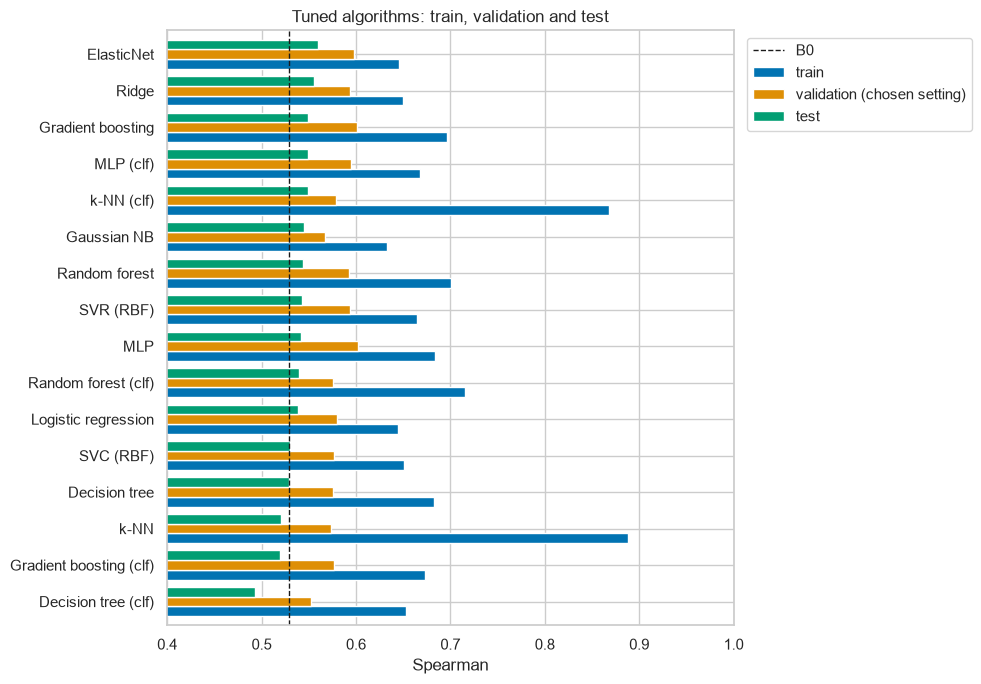

In [16]:
# score on the data the model was trained on, on the validation seasons that chose its hyperparameters, and on the season it never saw
gap = pd.DataFrame({n: {"train": r["folds"]["train_spearman"].mean(), "validation (chosen setting)": r["folds"]["inner"].mean(),
                        "test": tuned_scores[n]["spearman"].mean()} for n, r in TUNED.items()}).T.sort_values("test")
ax = gap.plot.barh(figsize=(10, 7), width=0.8)
ax.axvline(reference.mean(), color="k", ls="--", lw=1, label="B0")
ax.set(title="Tuned algorithms: train, validation and test", xlabel="Spearman", xlim=(0.4, 1.0))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
gap.assign(**{"validation - test": gap["validation (chosen setting)"] - gap["test"], "train - test": gap["train"] - gap["test"]}).sort_values("train - test")

**Complexity.** The curves train the algorithm once per season, without tuning, and let its flexibility grow. They show the textbook pattern:

- **Tree (depth).** The training Spearman grows from 0.57 to 0.84 as the tree gets deeper, while the test one peaks at depth 4 to 5 (0.53, the level of B0) and falls to 0.45 at depth 10. After depth 5 the tree memorises luck.
- **k-NN (neighbours).** With one neighbour the training score is 1 (every team is its own neighbour) and the test score is 0.33. The gap shrinks from 0.67 to 0.08 at 160 neighbours. It is the clearest case of variance, and it is solved by smoothing and not by adding data.
- **Boosting (trees).** The training Spearman rises with every tree (0.68 to 0.81), the test score is highest at the start (0.555) and slowly falls to 0.52 at 300 trees.
- **Ridge (penalty).** The training score is flat at 0.65 and only falls for very large penalties; the test score is flat at 0.56 and reaches the level of B0 for `alpha` of 1000 or more. A linear model with 12 features cannot overfit much, but it already fits about 0.09 more in training than it predicts in test: that is the luck of the seasons it has seen.

**Tuned models.** The bars and the table show, for the setting that tuning chose, the score on the seasons the model was trained on, on the validation seasons that chose it, and on the season it never saw. The order is train > validation > test for every algorithm.

- **Training minus test** goes from 0.085 (ElasticNet) to 0.18 (random forest), and is 0.32 and 0.37 for the two k-NN, which keep the training rows. The linear models, naive Bayes and the logistic regression have the smallest gaps (0.085 to 0.106).
- **Validation minus test** is 0.02 to 0.06 for all of them. It is the optimism of choosing the best of many combinations on a few seasons (section 6), and the reason why a score used for tuning cannot be reported as the result.
- **The gap does not order the algorithms by their test score.** The random forest, boosting and the single tree have similar gaps (about 0.15) and different test scores (0.544, 0.550 and 0.529), and the k-NN classifier, the second most overfitted (0.32), is among the best on test (0.549). The most regularised models (ElasticNet, Ridge) are on top, but by a margin that is inside the noise (section 7).

### 8.3 The function that each algorithm learned

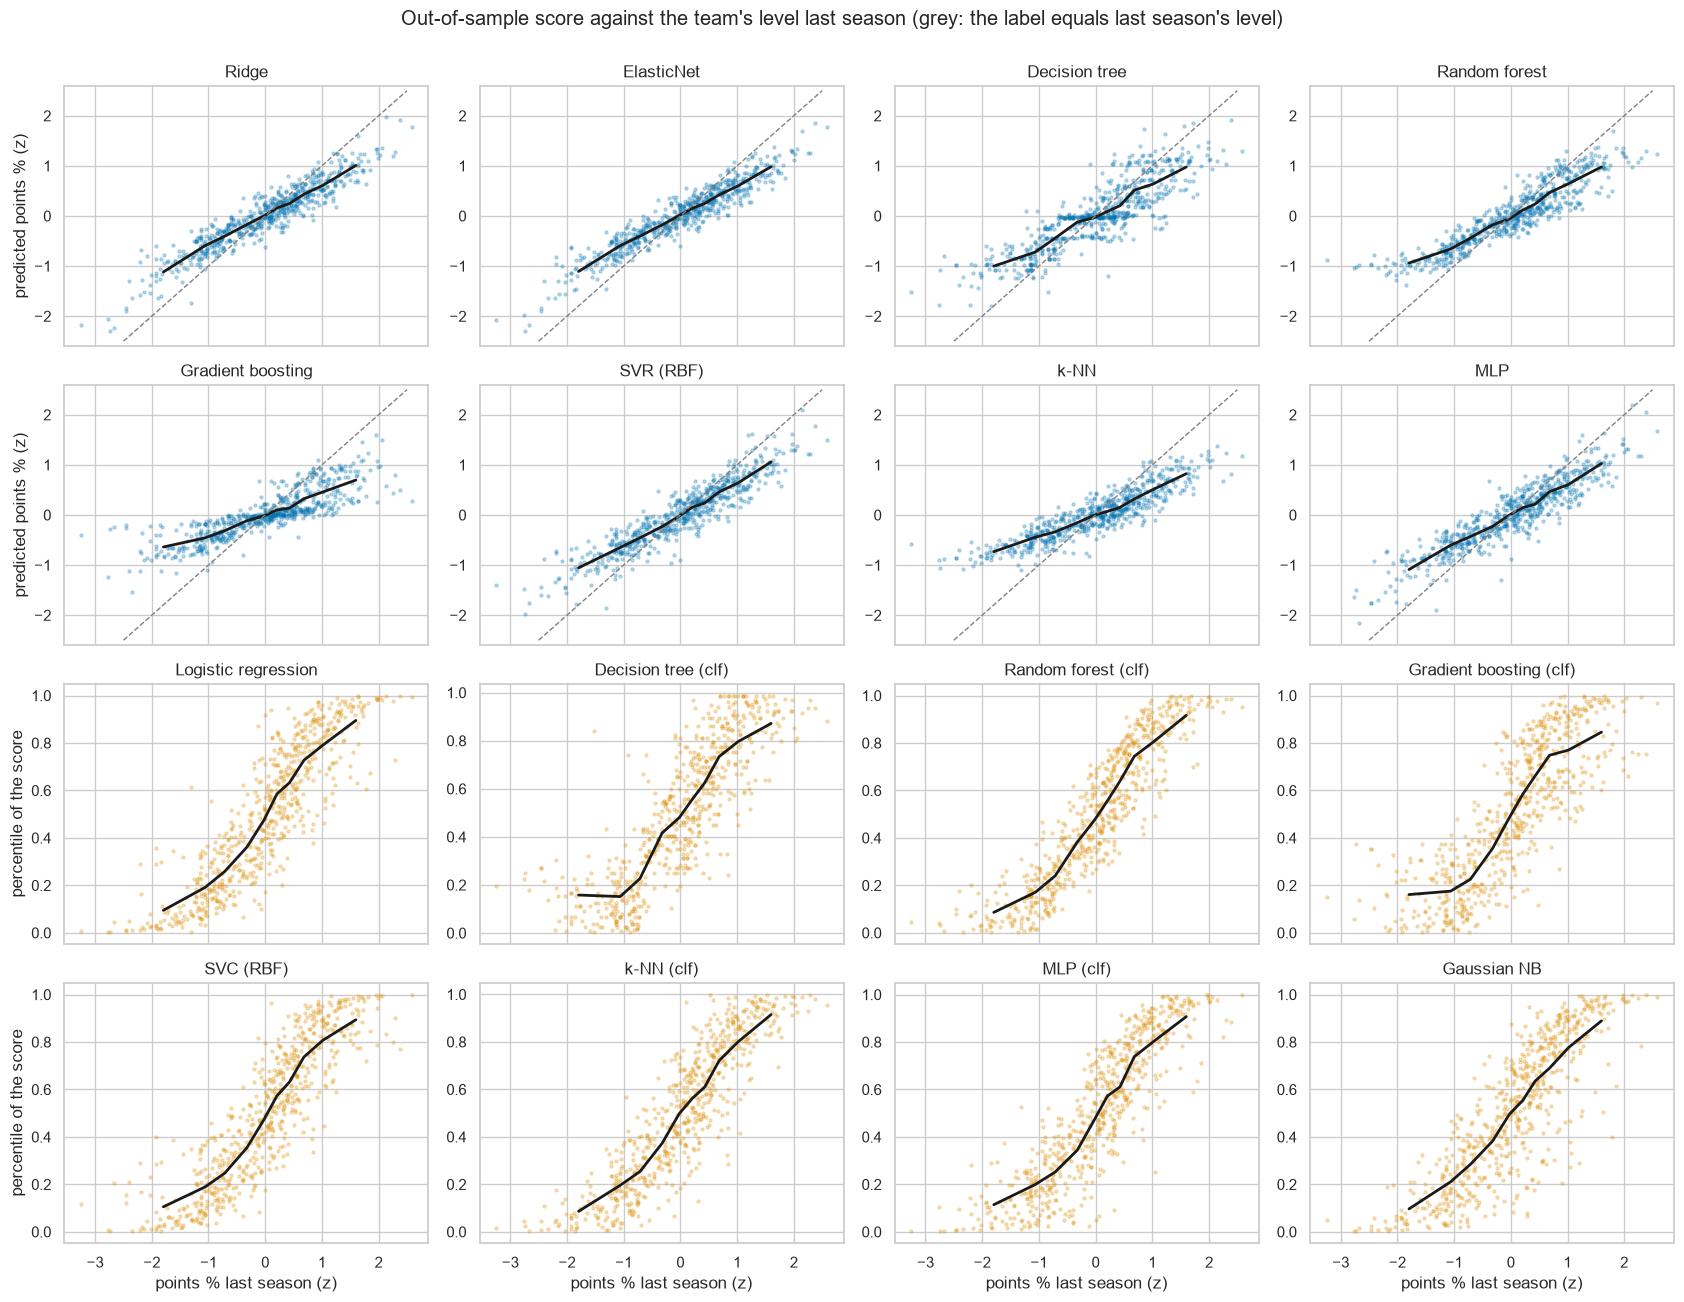

In [17]:
# What each algorithm learned about the team's past: its out-of-sample score against the points % of the team last season.
# Every point is a team-season of 1985-2009 predicted by a model that had not seen that season; the line is the mean in 10 groups of equal size.
past = panel[["year", "tmID", "pts_pct_z_lag1"]]
fig, axes = plt.subplots(4, 4, figsize=(17, 13), sharex=True)
for ax, n in zip(axes.flat, MODELS):
    d = past.merge(TUNED[n]["preds"][["year", "tmID", "score"]], on=["year", "tmID"]).dropna()
    regression = TASK_OF[n] == "regression"
    d["shown"] = d["score"] if regression else d["score"].rank(pct=True)      # classifiers: percentile of the score, whose scale is arbitrary
    ax.scatter(d["pts_pct_z_lag1"], d["shown"], s=5, alpha=0.25, color=COLORS[n])
    line = d.groupby(pd.qcut(d["pts_pct_z_lag1"], 10), observed=True)[["pts_pct_z_lag1", "shown"]].mean()
    ax.plot(line["pts_pct_z_lag1"], line["shown"], color="k", lw=2)
    if regression:
        ax.plot([-2.5, 2.5], [-2.5, 2.5], color="grey", ls="--", lw=1)
        ax.set_ylim(-2.6, 2.6)
    ax.set_title(n)
for ax in axes[-1]:
    ax.set_xlabel("points % last season (z)")
for ax in axes[:, 0]:
    ax.set_ylabel("predicted points % (z)" if ax is axes[0, 0] or ax is axes[1, 0] else "percentile of the score")
fig.suptitle("Out-of-sample score against the team's level last season (grey: the label equals last season's level)", y=1.0)
plt.tight_layout()

- **The linear algorithms, SVR and the MLP learn almost the same function:** a line (with a slight curve in the SVR and the MLP) that is about 0.6 times as steep as the diagonal. A team that was one standard deviation above the league last season is expected to be about 0.6 above it this season. This is the regression to the mean of section 6.1 of the EDA, and these models give nearly the same order to the teams.
- **The trees draw steps.** The single tree has few distinct values (a wide band of teams share the same prediction near 0, so there are many ties), the forest smooths those steps, and the boosting, with shallow trees and a low learning rate, gives the flattest line (a slope of about 0.4) with a lot of vertical spread, which suggests that it also relies on other features. The lack of resolution of a single tree is one reason why it is not better than B0.
- **k-NN** gives a jagged line, flatter than the linear ones: the average of 80 neighbours in 12 dimensions is pulled towards the mean.
- **The classifiers** (shown as the percentile of the score, whose scale is arbitrary) separate the best and the worst teams and are less sure in the middle, where it is hardest to know on which side of the median a team will end. The decision tree and the boosting leave a flat floor under the weakest teams (percentile 0.15): they do not tell the bad ones apart.

## 9. What this notebook does not cover

This notebook is limited on purpose. What is missing for the modelling of task (a):

- **Feature work.** All the runs use the 12 features of `02_data_prep.ipynb` as they are. Feature selection (filter and wrapper, inside the training folds), feature sets, and the roster, goalie and coach features listed in section 7 of that notebook are still to be tried. Nothing here depends on the list of features, so the notebook can be run again when it grows.
- **The choice of the final model.** Nothing was chosen. The differences between the best algorithms are inside the noise (section 7), the 16 algorithms were compared on the same 24 seasons, and picking a winner on them would be slightly optimistic. It needs a final assessment on seasons that were not used to choose, and a simple model (ElasticNet or Ridge) is the natural starting point.
- **Variants that were not tried.** The label (the rank directly, the points percentage inside the conference, three tiers for the classification), a limited training window and an ensemble of the best algorithms.
- **Interpretation.** Feature importance and the analysis of white-box models (coefficients, tree rules) in domain terms.